<a href="https://colab.research.google.com/github/unknxwNS/Ihopeitworks/blob/main/%D0%9C%D1%96%D1%85%D0%B0%D0%BB%D1%8C%D0%BE%D0%B2_%D0%A2%D0%BD_%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** — окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


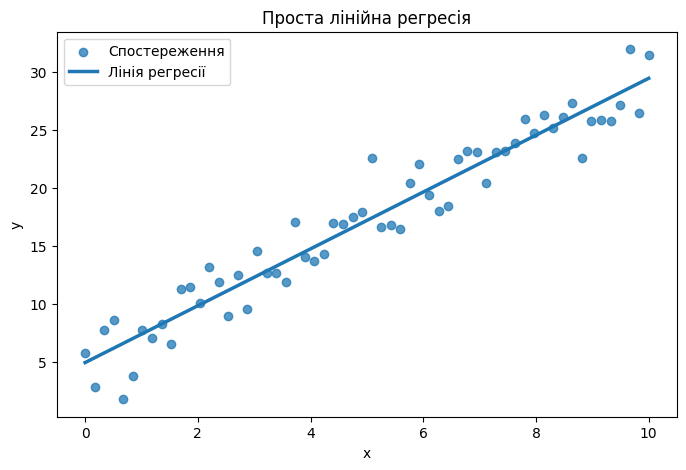

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [ ]:
X_new = np.array([2, 5, 8]).reshape(-1, 1)

predictions = simple_model.predict(X_new)

results = pd.DataFrame({
    'x': X_new.ravel(),
    'prediction': predictions
})

print(results)


   x  prediction
0  2    9.809730
1  5   17.163214
2  8   24.516697


## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [ ]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [ ]:

x2 = np.array([2, 4, 6, 8, 10], dtype=float)
y2 = np.array([7, 11, 16, 19, 25], dtype=float)

# Середні значення
x2_bar = x2.mean()
y2_bar = y2.mean()

# Ручне обчислення коефіцієнтів
b1_2 = ((x2 - x2_bar) * (y2 - y2_bar)).sum() / ((x2 - x2_bar) ** 2).sum()
b0_2 = y2_bar - b1_2 * x2_bar

# Перевірка за допомогою LinearRegression
model2 = LinearRegression()
model2.fit(x2.reshape(-1, 1), y2)

print(f'Ручний розрахунок: b0 = {b0_2:.4f}, b1 = {b1_2:.4f}')
print(f'scikit-learn:     b0 = {model2.intercept_:.4f}, b1 = {model2.coef_[0]:.4f}')


Ручний розрахунок: b0 = 2.4000, b1 = 2.2000
scikit-learn:     b0 = 2.4000, b1 = 2.2000


## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [ ]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [ ]:
y

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [ ]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)



`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [ ]:
mae_baseline = mean_absolute_error(y_test, baseline_pred)
rmse_baseline = root_mean_squared_error(y_test, baseline_pred)
r2_baseline = r2_score(y_test, baseline_pred)


mae_linear = mean_absolute_error(y_test, linear_pred)
rmse_linear = root_mean_squared_error(y_test, linear_pred)
r2_linear = r2_score(y_test, linear_pred)

comparison = pd.DataFrame({
    'MAE': [mae_baseline, mae_linear],
    'RMSE': [rmse_baseline, rmse_linear],
    'R2': [r2_baseline, r2_linear]
}, index=['DummyRegressor', 'LinearRegression'])

display(comparison.round(3))


,MAE,RMSE,R2
DummyRegressor,64.006,73.222,-0.012
LinearRegression,42.794,53.853,0.453


**Ваш висновок:**  
Модель LinearRegression показала кращі результати порівняно з DummyRegressor, оскільки враховує ознаки для прогнозування цільового значення. MAE та RMSE характеризують величину помилок, а R² показує, наскільки добре модель пояснює зміну цільової змінної. На графіку залишків точки мають бути розташовані навколо нульової лінії, а відсутність чіткої закономірності свідчить про прийнятну роботу моделі.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

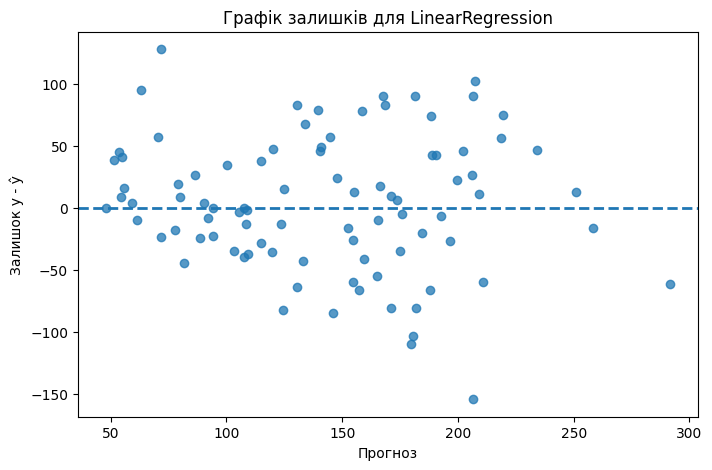

In [ ]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


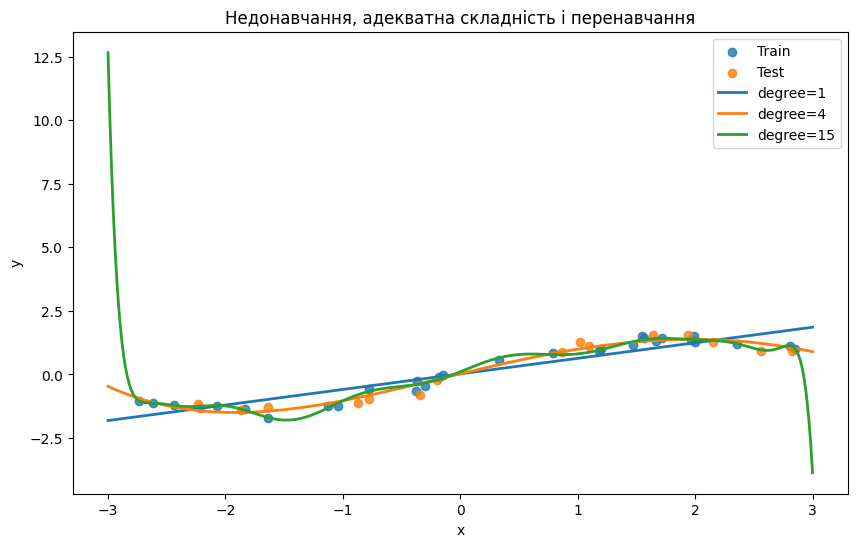

In [ ]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [ ]:

degrees = [1, 2, 4, 6, 10, 15]

results = []
models_poly = {}

for degree in degrees:
    model, res = fit_polynomial(degree)
    models_poly[degree] = model
    results.append(res)

results_df = pd.DataFrame(results)[
    ['degree', 'train_rmse', 'test_rmse']
]

display(results_df.round(4))

best_degree = results_df.loc[
    results_df['test_rmse'].idxmin(), 'degree'
]

print(f'Найкращий ступінь за test_rmse: {best_degree}')
print(
    f"Мінімальний test_rmse: "
    f"{results_df['test_rmse'].min():.4f}"
)


,degree,train_rmse,test_rmse
0,1,0.3929,0.4654
1,2,0.3928,0.4640
2,4,0.1450,0.2032
3,6,0.1371,0.1963
4,10,0.1291,0.1918
5,15,0.0910,0.2443


Найкращий ступінь за test_rmse: 10
Мінімальний test_rmse: 0.1918


## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso — L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [ ]:
# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.626287568895194


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [ ]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501726, 'RMSE': 53.777454065343896, 'R2': 0.45414652070698225, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [ ]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [ ]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [ ]:

# Створюємо чотири моделі
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Ridge(alpha=1.0))
    ]),
    'Lasso': Pipeline([
        ('scale', StandardScaler()),
        ('reg', Lasso(alpha=1.0, max_iter=20000))
    ]),
    'ElasticNet': Pipeline([
        ('scale', StandardScaler()),
        ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000))
    ])
}

# Навчання та оцінювання моделей
results_models = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results_models.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': root_mean_squared_error(y_test, pred),
        'R2': r2_score(y_test, pred)
    })

# Порівняльна таблиця
comparison_models = pd.DataFrame(results_models)
display(comparison_models.round(3))


,Model,MAE,RMSE,R2
0,LinearRegression,42.794,53.853,0.453
1,Ridge,42.812,53.777,0.454
2,Lasso,42.803,53.147,0.467
3,ElasticNet,42.873,53.539,0.459


## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [ ]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [ ]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [ ]:

# Pipeline для Lasso
lasso_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(max_iter=50000)),
])

# 20 значень alpha в логарифмічній шкалі
param_grid_lasso = {
    'reg__alpha': np.logspace(-3, 1, 20)
}

lasso_search = GridSearchCV(
    lasso_search_model,
    param_grid=param_grid_lasso,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

lasso_search.fit(X_train, y_train)

print('Найкраще alpha для Lasso:', lasso_search.best_params_['reg__alpha'])
print('CV RMSE Lasso:', -lasso_search.best_score_)
print('Test RMSE Lasso:', root_mean_squared_error(
    y_test, lasso_search.predict(X_test)
))

print('\nНайкраще alpha для Ridge:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE Ridge:', -ridge_search.best_score_)
print('Test RMSE Ridge:', root_mean_squared_error(
    y_test, ridge_search.predict(X_test)
))


Найкраще alpha для Lasso: 0.5455594781168515
CV RMSE Lasso: 55.348748431919475
Test RMSE Lasso: 53.423673049226494

Найкраще alpha для Ridge: 1.0
CV RMSE Ridge: 55.374175368673455
Test RMSE Ridge: 53.777454065343896


## 16. Як регуляризація змінює коефіцієнти

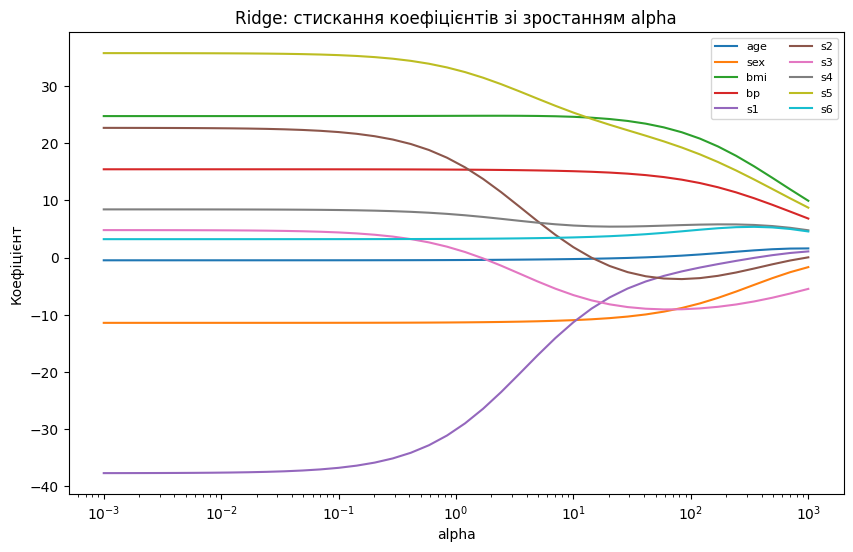

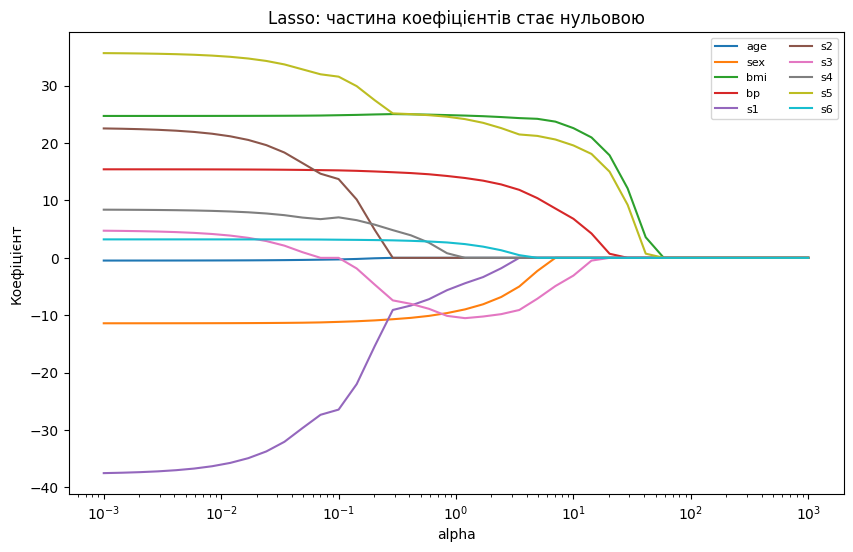

In [ ]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)  # дуже сильна кореляція
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})

# Додаємо кілька пропусків.
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE', mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 10925.278371503928
Housing R2: 0.9068908686435069
Housing MAE: 8737.023097309464
MAPE 0.07276440135248957


In [ ]:
housing

,area,rooms,age,district,condition
0,81.094342,4,17.0,south,good
1,54.200318,2,66.0,south,good
2,90.009024,2,37.0,center,needs_repair
3,93.811294,2,21.0,south,good
4,35.979296,3,29.0,south,new
...,...,...,...,...,...
295,78.530248,4,30.0,center,needs_repair
296,80.919880,5,45.0,center,needs_repair
297,67.561708,3,38.0,center,needs_repair
298,39.865564,3,67.0,south,good


In [ ]:
price

,0
0,146888.018855
1,43872.771974
2,175189.836338
3,145447.579696
4,58699.634461
...,...
295,179796.834387
296,197085.341513
297,166868.377770
298,32562.347956


### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [ ]:

# 1. Додаємо нову категоріальну ознаку
rng = np.random.default_rng(RANDOM_STATE)

housing['condition'] = rng.choice(
    ['new', 'good', 'needs_repair'],
    size=len(housing),
    p=[0.2, 0.6, 0.2]
)

# 2. Повторно розділяємо дані
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

# 3. Оновлюємо категоріальні ознаки
categorical_features = ['district', 'condition']

# 4. Створюємо обробку даних
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

# 5. Створюємо та навчаємо модель
housing_model_updated = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model_updated.fit(X_h_train, y_h_train)
housing_pred_updated = housing_model_updated.predict(X_h_test)

# 6. Виводимо метрики оновленої моделі
print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred_updated))
print('Housing R2:', r2_score(y_h_test, housing_pred_updated))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred_updated))
print('Housing MAPE:', mean_absolute_percentage_error(y_h_test, housing_pred_updated))


Housing RMSE: 10832.529583135261
Housing R2: 0.9084650350357727
Housing MAE: 8730.643205124728
Housing MAPE: 0.07280516816661159


## 19. Навчальні криві

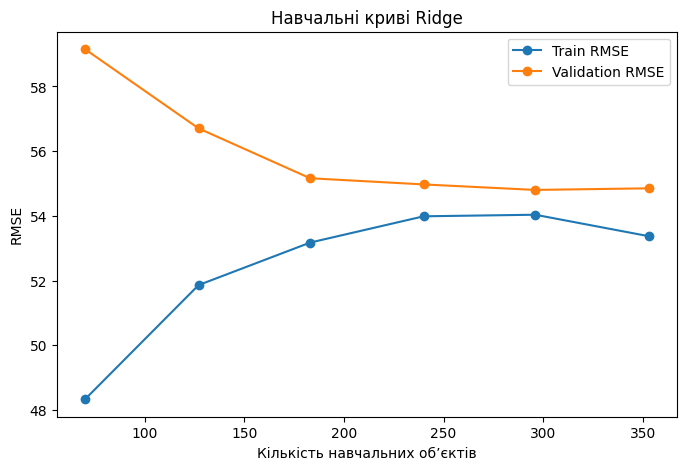

In [ ]:
learning_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=ridge_search.best_params_['reg__alpha'])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X,
    y,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse_curve, marker='o', label='Validation RMSE')
plt.xlabel('Кількість навчальних об’єктів')
plt.ylabel('RMSE')
plt.title('Навчальні криві Ridge')
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [ ]:
# 1. Test відкладаємо один раз.
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Вибір моделі відбувається тільки всередині train за CV.
model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
)
search.fit(X_final_train, y_final_train)

# 3. Лише після завершення підбору оцінюємо test.
final_pred = search.predict(X_final_test)

print('Найкращі параметри:', search.best_params_)
print('CV RMSE:', -search.best_score_)
print('Test metrics:', regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test metrics: {'MAE': 42.81393247843441, 'MSE': 2888.4712888244917, 'RMSE': 53.74450007977087, 'R2': 0.4548152967432053, 'MAPE': np.float64(37.42858410670238)}


# 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити **самостійно**, використовуючи попередні приклади лише як орієнтир.

Вимоги до роботи:

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net — `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік `фактичні значення → прогноз` та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [ ]:

# Крок 1. Дані

from sklearn.datasets import load_diabetes
import pandas as pd

diabetes = load_diabetes(as_frame=True)

X_task = diabetes.data.copy()
y_task = diabetes.target.copy()

print('Розмір X_task:', X_task.shape)
print('Розмір y_task:', y_task.shape)

display(X_task.head())
display(y_task.head())


Розмір X_task: (442, 10)
Розмір y_task: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0


### Крок 2. Train/test

In [ ]:

from sklearn.model_selection import train_test_split

X_train_task, X_test_task, y_train_task, y_test_task = train_test_split(
    X_task, y_task,
    test_size=0.2,
    random_state=42
)

print('Train:', X_train_task.shape)
print('Test:', X_test_task.shape)


Train: (353, 10)
Test: (89, 10)


### Крок 3. Baseline

In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

dummy_task = DummyRegressor(strategy='mean')
linear_task = LinearRegression()

dummy_task.fit(X_train_task, y_train_task)
linear_task.fit(X_train_task, y_train_task)

dummy_pred = dummy_task.predict(X_test_task)
linear_pred = linear_task.predict(X_test_task)


### Крок 4. Метрики

In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

def metrics_task(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    }

baseline_results = pd.DataFrame(
    [
        metrics_task(y_test_task, dummy_pred),
        metrics_task(y_test_task, linear_pred)
    ],
    index=['DummyRegressor', 'LinearRegression']
)

display(baseline_results.round(3))


,MAE,RMSE,R2
DummyRegressor,64.006,73.222,-0.012
LinearRegression,42.794,53.853,0.453


### Крок 5. Ridge, Lasso, Elastic Net

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet

ridge_task = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0))
])

lasso_task = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=0.1, max_iter=50000))
])

elastic_task = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50000))
])

for name, model in [
    ('Ridge', ridge_task),
    ('Lasso', lasso_task),
    ('ElasticNet', elastic_task)
]:
    model.fit(X_train_task, y_train_task)
    print(f'{name} навчено')


Ridge навчено
Lasso навчено
ElasticNet навчено


### Крок 6. Крос-валідація

In [ ]:

from sklearn.model_selection import KFold, cross_val_score

cv_task = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_cv_task = {
    'DummyRegressor': dummy_task,
    'LinearRegression': linear_task,
    'Ridge': ridge_task,
    'Lasso': lasso_task,
    'ElasticNet': elastic_task
}

cv_results_task = []

for name, model in models_cv_task.items():
    scores = cross_val_score(
        model,
        X_train_task,
        y_train_task,
        cv=cv_task,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    cv_results_task.append({
        'Модель': name,
        'CV RMSE': -scores.mean(),
        'Стандартне відхилення': scores.std()
    })

cv_table_task = pd.DataFrame(cv_results_task).sort_values('CV RMSE')

display(cv_table_task.round(3))


,Модель,CV RMSE,Стандартне відхилення
3,Lasso,55.354,2.356
2,Ridge,55.374,2.373
1,LinearRegression,55.395,2.361
4,ElasticNet,55.433,2.351
0,DummyRegressor,78.134,5.638


### Крок 7. Підбір гіперпараметрів

In [ ]:

from sklearn.model_selection import KFold, GridSearchCV
import numpy as np

cv_task = KFold(n_splits=5, shuffle=True, random_state=42)

# Ridge
ridge_search_task = GridSearchCV(
    Pipeline([
        ('scale', StandardScaler()),
        ('reg', Ridge())
    ]),
    param_grid={'reg__alpha': np.logspace(-3, 3, 20)},
    scoring='neg_root_mean_squared_error',
    cv=cv_task,
    n_jobs=-1
)
ridge_search_task.fit(X_train_task, y_train_task)

# Lasso
lasso_search_task = GridSearchCV(
    Pipeline([
        ('scale', StandardScaler()),
        ('reg', Lasso(max_iter=50000))
    ]),
    param_grid={'reg__alpha': np.logspace(-3, 1, 25)},
    scoring='neg_root_mean_squared_error',
    cv=cv_task,
    n_jobs=-1
)
lasso_search_task.fit(X_train_task, y_train_task)

# ElasticNet
elastic_search_task = GridSearchCV(
    Pipeline([
        ('scale', StandardScaler()),
        ('reg', ElasticNet(max_iter=50000))
    ]),
    param_grid={
        'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
        'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
    },
    scoring='neg_root_mean_squared_error',
    cv=cv_task,
    n_jobs=-1
)
elastic_search_task.fit(X_train_task, y_train_task)

print('Ridge:', ridge_search_task.best_params_)
print('Lasso:', lasso_search_task.best_params_)
print('ElasticNet:', elastic_search_task.best_params_)


Ridge: {'reg__alpha': np.float64(0.6951927961775606)}
Lasso: {'reg__alpha': np.float64(0.1467799267622069)}
ElasticNet: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}


### Крок 8. Фінальна таблиця моделей

In [ ]:

models_task = {
    'DummyRegressor': dummy_task,
    'LinearRegression': linear_task,
    'Ridge': ridge_search_task.best_estimator_,
    'Lasso': lasso_search_task.best_estimator_,
    'ElasticNet': elastic_search_task.best_estimator_
}

rows_task = []

for name, model in models_task.items():
    cv_rmse = -cross_val_score(
        model,
        X_train_task,
        y_train_task,
        cv=cv_task,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    ).mean()

    model.fit(X_train_task, y_train_task)
    pred = model.predict(X_test_task)
    metrics = metrics_task(y_test_task, pred)

    rows_task.append({
        'Модель': name,
        'CV RMSE': cv_rmse,
        'Test MAE': metrics['MAE'],
        'Test RMSE': metrics['RMSE'],
        'Test R2': metrics['R2']
    })

results_task = pd.DataFrame(rows_task).sort_values('CV RMSE')
display(results_task.round(3))

best_name_task = results_task.iloc[0]['Модель']
best_model_task = models_task[best_name_task]
best_pred_task = best_model_task.predict(X_test_task)

print('Найкраща модель:', best_name_task)


,Модель,CV RMSE,Test MAE,Test RMSE,Test R2
3,Lasso,55.349,42.815,53.686,0.456
4,ElasticNet,55.369,42.814,53.745,0.455
2,Ridge,55.375,42.808,53.795,0.454
1,LinearRegression,55.395,42.794,53.853,0.453
0,DummyRegressor,78.134,64.006,73.222,-0.012


Найкраща модель: Lasso


### Крок 9. Візуалізація найкращої моделі

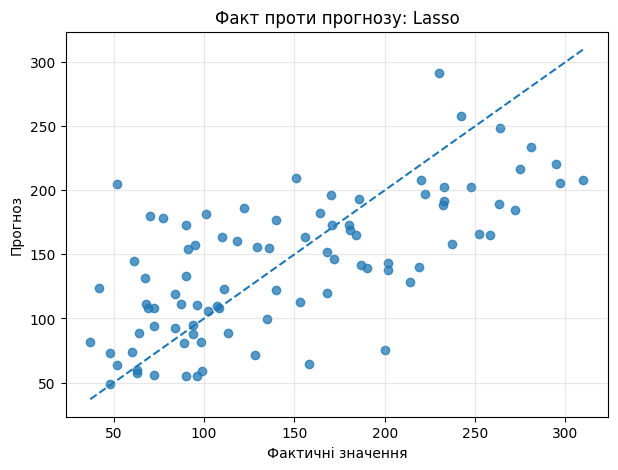

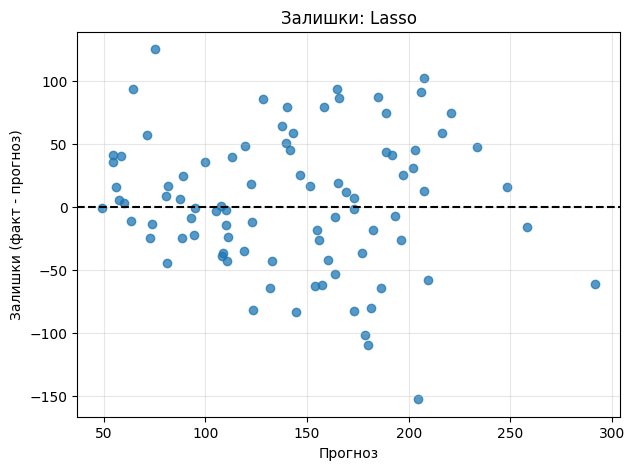

In [ ]:

import matplotlib.pyplot as plt

# Графік 1: фактичні значення проти прогнозу
plt.figure(figsize=(7, 5))
plt.scatter(y_test_task, best_pred_task, alpha=0.75)

min_val = min(y_test_task.min(), best_pred_task.min())
max_val = max(y_test_task.max(), best_pred_task.max())

plt.plot([min_val, max_val], [min_val, max_val], '--')
plt.xlabel('Фактичні значення')
plt.ylabel('Прогноз')
plt.title(f'Факт проти прогнозу: {best_name_task}')
plt.grid(alpha=0.3)
plt.show()

# Графік 2: прогноз проти залишків
residuals_task = y_test_task - best_pred_task

plt.figure(figsize=(7, 5))
plt.scatter(best_pred_task, residuals_task, alpha=0.75)
plt.axhline(0, linestyle='--', color='black')
plt.xlabel('Прогноз')
plt.ylabel('Залишки (факт - прогноз)')
plt.title(f'Залишки: {best_name_task}')
plt.grid(alpha=0.3)
plt.show()


### Крок 10. Коефіцієнти

Коефіцієнти для стандартизованих ознак


,Ознака,Коефіцієнт,Абсолютне значення
8,s5,28.6527,28.6527
4,s1,-27.0137,27.0137
2,bmi,25.9122,25.9122
3,bp,16.5911,16.5911
5,s2,11.2079,11.2079
1,sex,-11.1933,11.1933
7,s4,10.4001,10.4001
9,s6,2.3934,2.3934
0,age,1.6918,1.6918
6,s3,-0.0000,0.0000


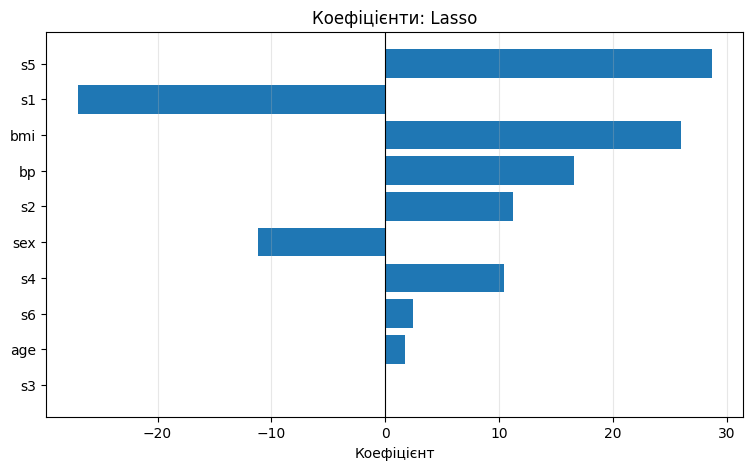

In [ ]:

if best_name_task == 'DummyRegressor':
    print('DummyRegressor не має коефіцієнтів ознак.')
else:
    if best_name_task in ['Ridge', 'Lasso', 'ElasticNet']:
        coefficients_task = best_model_task.named_steps['reg'].coef_
        print('Коефіцієнти для стандартизованих ознак')
    else:
        coefficients_task = best_model_task.coef_
        print('Коефіцієнти LinearRegression у вихідному масштабі')

    coef_table_task = pd.DataFrame({
        'Ознака': X_task.columns,
        'Коефіцієнт': coefficients_task
    })

    coef_table_task['Абсолютне значення'] = (
        coef_table_task['Коефіцієнт'].abs()
    )

    coef_table_task = coef_table_task.sort_values(
        'Абсолютне значення',
        ascending=False
    )

    display(coef_table_task.round(4))

    plt.figure(figsize=(9, 5))
    plt.barh(
        coef_table_task['Ознака'],
        coef_table_task['Коефіцієнт']
    )
    plt.axvline(0, color='black', linewidth=0.8)
    plt.xlabel('Коефіцієнт')
    plt.title(f'Коефіцієнти: {best_name_task}')
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)
    plt.show()


### Крок 11. Підсумковий висновок

У новій Markdown-комірці після цієї сформулюйте висновок обсягом 5–8 речень. Обов'язково зазначте:

- яка модель показала найкращий результат;
- за якою метрикою виконано вибір;
- чи є ознаки перенавчання;
- як регуляризація вплинула на результат;
- чому test не використовувався під час підбору гіперпараметрів.

У ході практичної роботи було досліджено моделі регресії для прогнозування на наборі даних Diabetes. Найкращу модель обрано за найменшим середнім значенням CV RMSE під час п'ятифолдової крос-валідації. Регуляризація Ridge, Lasso та ElasticNet допомогла контролювати коефіцієнти моделей і могла покращити точність прогнозування. Тестову вибірку не використовували під час підбору гіперпараметрів, щоб отримати незалежну оцінку якості моделі. Отже, крос-валідація та тестування дали змогу порівняти моделі й визначити найбільш ефективну для цього набору даних.

## Контрольні питання після практики

1. Чому `StandardScaler` для Ridge/Lasso/Elastic Net доцільно розміщувати всередині `Pipeline`?
2. Чим відрізняється train-помилка від validation/test-помилки?
3. За якими ознаками можна розпізнати перенавчання?
4. Чим L1-регуляризація відрізняється від L2-регуляризації?
5. Чому `alpha` не можна підбирати за тестовою вибіркою?
6. Яку роль відіграє `l1_ratio` в Elastic Net?
7. Чому великий за модулем коефіцієнт не завжди означає, що ознака є найважливішою?
8. У чому перевага крос-валідації порівняно з одним випадковим validation-розбиттям?

In [ ]:
import pandas as pd
import requests
from io import StringIO

url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0
